# B1 – Lingkungan Kerja dan Formulasi Masalah

**Studi kasus:** SIMUTEH – Pemantauan Bercak Daun Teh  
**Nama:** Ramadi Hayqal Dwinugraha  
**NIM:** 2230511115 · **Kelas:** 7A · **SEED:** 1115

Notebook ini menyiapkan lingkungan, memeriksa dataset sintetis, merumuskan masalah, membuat diagram pipeline, dan mencatat risiko *responsible computer vision*. Jalankan sel dari atas ke bawah.

**Lokasi Google Drive:** simpan folder repository ini di `My Drive/Colab Notebooks/simuteh-2230511115/`. Buka notebook dari subfolder `notebook/`. Sel persiapan akan memasang Google Drive di Colab.

> **Catatan Google Colab:** Jalankan sel persiapan terlebih dahulu dan izinkan akses Google Drive. Pastikan folder `simuteh-2230511115` lengkap berada di `Drive Saya/Colab Notebooks/`. Jika sebelumnya pernah menjalankan versi lama, pilih **Runtime → Restart session** lalu jalankan notebook dari atas.

## 1.1 Pemeriksaan lingkungan dan dataset

Jalankan notebook dari dalam folder repository `simuteh-2230511115/` atau dari subfolder `notebook/`. Dataset akan dibuat otomatis dari `src/buat_dataset_sintetis.py` bila belum tersedia.

In [6]:
from pathlib import Path
import sys, subprocess, json, time, platform, importlib.metadata
import importlib, ast, os

# Pustaka utama yang dipakai pada seluruh notebook. Google Colab umumnya sudah
# menyediakannya; requirements.txt tetap disediakan untuk lingkungan lain.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from IPython.display import display
from time import perf_counter

# 1) Pasang Google Drive (khusus Google Colab).
try:
    from google.colab import drive
    IN_COLAB = True
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

# 2) Temukan folder repository. Path yang mengandung spasi aman karena
#    seluruh operasi memakai pathlib, bukan pemisahan string shell.
DRIVE_NOTEBOOKS = Path("/content/drive/MyDrive/Colab Notebooks")
_kandidat = [
    DRIVE_NOTEBOOKS / "simuteh-2230511115",
    DRIVE_NOTEBOOKS / "simuteh-2230511115" / "simuteh-2230511115",  # jika folder ter-ekstrak ganda
    Path.cwd(),
    *Path.cwd().parents,
    Path("/content/simuteh-2230511115"),
]

# Tambahkan kandidat folder satu tingkat di bawah Colab Notebooks,
# berguna bila pengguna mengunggah folder dengan nama tambahan.
if DRIVE_NOTEBOOKS.exists():
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob("*/simuteh-2230511115")))
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob("*")))

def _folder_repository(p):
    return (p.is_dir()
            and (p / "src" / "utils_cv.py").is_file()
            and (p / "src" / "buat_dataset_sintetis.py").is_file())

ROOT = next((p.resolve() for p in _kandidat if _folder_repository(p)), None)
if ROOT is None:
    raise FileNotFoundError(
        "Folder repository SIMUTEH belum ditemukan. Pastikan folder "
        "simuteh-2230511115 (yang berisi src/, notebook/, data/, dan hasil/) "
        "sudah diunggah ke Google Drive > Drive Saya > Colab Notebooks. "
        "Jangan hanya mengunggah file .ipynb secara terpisah."
    )

SRC = ROOT / "src"
DATA = ROOT / "data" / "sintetis"
CITRA = DATA / "citra"
BERSIH = DATA / "bersih"
MASK_DAUN = DATA / "mask_daun"
MASK_BERCAK = DATA / "mask_bercak"
HASIL = ROOT / "hasil"
HASIL.mkdir(parents=True, exist_ok=True)
for _folder in (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK):
    _folder.mkdir(parents=True, exist_ok=True)

# 3) Hindari modul lama yang mungkin masih tersimpan di memori Colab
#    setelah pengguna mengganti file src atau berpindah notebook.
for _nama_modul in ("buat_dataset_sintetis", "utils_cv", "praproses"):
    sys.modules.pop(_nama_modul, None)
importlib.invalidate_caches()
_src_text = str(SRC.resolve())
sys.path[:] = [_src_text] + [p for p in sys.path if str(p) != _src_text]

# 4) Ambil SEED dari file sumber tanpa mengimpor modul generator.
#    Ini menghindari ImportError bila kernel Colab menyimpan modul lama.
SCRIPT_DATASET = SRC / "buat_dataset_sintetis.py"
def _baca_konstanta_seed(path):
    tree = ast.parse(path.read_text(encoding="utf-8"), filename=str(path))
    for node in tree.body:
        if isinstance(node, ast.Assign):
            if any(isinstance(target, ast.Name) and target.id == "SEED" for target in node.targets):
                return ast.literal_eval(node.value)
        elif isinstance(node, ast.AnnAssign) and isinstance(node.target, ast.Name) and node.target.id == "SEED":
            return ast.literal_eval(node.value)
    raise ValueError(
        f"Konstanta SEED tidak ditemukan di {path}. Ganti file src/buat_dataset_sintetis.py "
        "dengan versi repository SIMUTEH yang terbaru."
    )

NIM = "2230511115"
SEED = _baca_konstanta_seed(SCRIPT_DATASET)
if str(SEED) != NIM[-4:]:
    raise ValueError(
        f"SEED pada src/buat_dataset_sintetis.py adalah {SEED}, sedangkan "
        f"empat digit terakhir NIM adalah {NIM[-4:]}. Periksa file sumber sebelum membuat dataset."
    )

# 5) Impor fungsi bantu dari lokasi src yang sudah dipastikan benar.
from utils_cv import baca, tampil, kontras_bercak, statistik

# 6) Buat ulang dataset hanya bila belum lengkap / label belum valid.
import pandas as pd
label_path = DATA / "label.csv"
subfolder_dataset = (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK)
dataset_lengkap = label_path.is_file()
if dataset_lengkap:
    try:
        _cek_label = pd.read_csv(label_path)
        dataset_lengkap = (
            len(_cek_label) == 60
            and _cek_label["nama_file"].nunique() == 60
            and all(sum(1 for _ in folder.glob("teh_*.png")) == 60 for folder in subfolder_dataset)
        )
    except Exception:
        dataset_lengkap = False

if not dataset_lengkap:
    print("Dataset belum lengkap. Membuat 60 citra sintetis menggunakan SEED", SEED)
    subprocess.run([sys.executable, str(SCRIPT_DATASET)], cwd=str(ROOT), check=True)

label = pd.read_csv(label_path)
assert len(label) == 60 and label["nama_file"].nunique() == 60, "Dataset harus berisi 60 citra unik."
for _folder in subfolder_dataset:
    _jumlah = sum(1 for _ in _folder.glob("teh_*.png"))
    assert _jumlah == 60, f"Folder {_folder.name} harus berisi 60 gambar, ditemukan {_jumlah}."

KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

print("Repository:", ROOT)
print("SEED:", SEED, "| Jumlah citra:", len(label), "| Ukuran target: 640 x 480")


Repository: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115
SEED: 1115 | Jumlah citra: 60 | Ukuran target: 640 x 480


## 1.2 Uji struktur larik citra dan urutan warna BGR/RGB

Kode berikut mencetak `shape`, `dtype`, rentang intensitas, dan piksel `(y=100, x=200)` pada `teh_041.png`. Citra dibaca OpenCV dalam urutan BGR; Matplotlib mengharapkan RGB.

OpenCV: 4.14.0 | NumPy: 2.1.3 | scikit-image: 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 1 253
piksel (y=100, x=200), urutan BGR: [180 201 191]


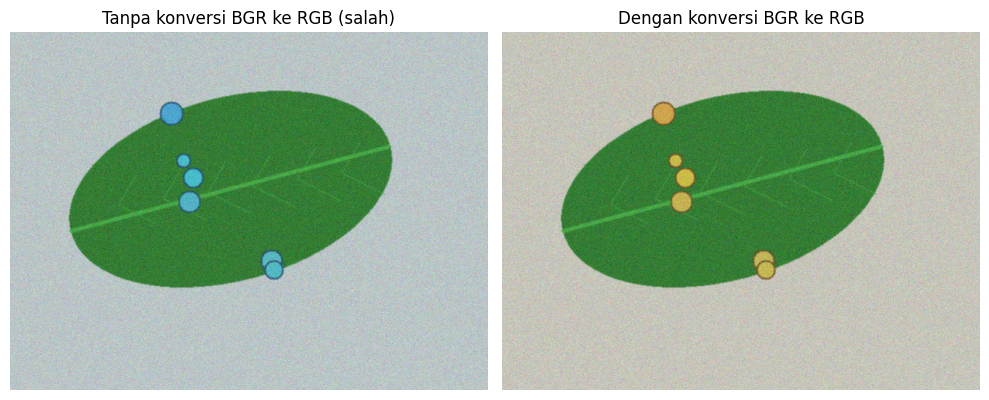

In [7]:
img = baca(CITRA / "teh_041.png")
print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__, "| scikit-image:", skimage.__version__)
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200), urutan BGR:", img[100, 200])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img); axes[0].set_title("Tanpa konversi BGR ke RGB (salah)"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[1].set_title("Dengan konversi BGR ke RGB"); axes[1].axis("off")
plt.tight_layout()
plt.savefig(HASIL / "b1_bgr_rgb.png", dpi=160, bbox_inches="tight")
plt.show()

## 1.3 Problem statement SIMUTEH

**Rumusan masalah (silakan sesuaikan dengan pemahaman sendiri):**

Bagi petugas sortir kelompok tani yang perlu memeriksa bercak penyakit pada daun teh secara cepat dan konsisten, SIMUTEH dibangun untuk menerima foto daun teh dari kamera telepon genggam dan menghasilkan kelas mutu (Sehat, Bercak Ringan, atau Bercak Berat) beserta perkiraan persentase luas bercak, sehingga petugas memperoleh alat bantu penilaian tanpa menghilangkan keputusan akhir manusia.

## 1.4 Diagram pipeline enam tahap

Setiap tahap mencantumkan masukan, proses, dan keluaran sesuai kasus daun teh.

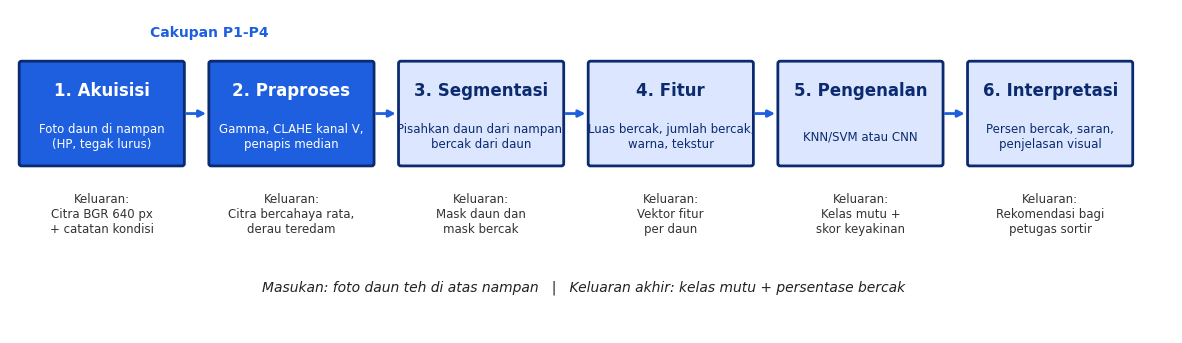

In [8]:
from matplotlib.patches import FancyBboxPatch

# Enam tahap pipeline SIMUTEH. Dua tahap pertama (Akuisisi dan Praproses)
# merupakan cakupan utama evaluasi P1-P4.
tahap = [
    ("1. Akuisisi", "Foto daun di nampan\n(HP, tegak lurus)", "Citra BGR 640 px\n+ catatan kondisi"),
    ("2. Praproses", "Gamma, CLAHE kanal V,\npenapis median", "Citra bercahaya rata,\nderau teredam"),
    ("3. Segmentasi", "Pisahkan daun dari nampan,\nbercak dari daun", "Mask daun dan\nmask bercak"),
    ("4. Fitur", "Luas bercak, jumlah bercak,\nwarna, tekstur", "Vektor fitur\nper daun"),
    ("5. Pengenalan", "KNN/SVM atau CNN", "Kelas mutu +\nskor keyakinan"),
    ("6. Interpretasi", "Persen bercak, saran,\npenjelasan visual", "Rekomendasi bagi\npetugas sortir"),
]

fig, ax = plt.subplots(figsize=(15, 4.2))
ax.set_xlim(0, 15.2)  # ruang tambahan agar kepala panah terakhir tidak terpotong
ax.set_ylim(0, 4.2)
ax.axis("off")

for i, (nm, proses, keluar) in enumerate(tahap):
    x = 0.15 + i * 2.48
    warna_box = "#1E5FE0" if i < 2 else "#DCE7FF"
    warna_teks = "white" if i < 2 else "#0B2A6F"

    ax.add_patch(
        FancyBboxPatch(
            (x, 2.2), 2.1, 1.3,
            boxstyle="round,pad=0.03",
            fc=warna_box,
            ec="#0B2A6F",
            lw=2,
        )
    )
    ax.text(
        x + 1.05, 3.15, nm,
        ha="center", va="center",
        fontsize=12, weight="bold", color=warna_teks,
    )
    ax.text(
        x + 1.05, 2.55, proses,
        ha="center", va="center",
        fontsize=8.5, color=warna_teks,
    )
    ax.text(
        x + 1.05, 1.55, "Keluaran:\n" + keluar,
        ha="center", va="center",
        fontsize=8.5, color="#333333",
    )

    if i < 5:
        ax.annotate(
            "",
            xy=(x + 2.45, 2.85),
            xytext=(x + 2.12, 2.85),
            arrowprops=dict(arrowstyle="-|>", color="#1E5FE0", lw=2),
        )

ax.text(
    7.5, 0.55,
    "Masukan: foto daun teh di atas nampan   |   Keluaran akhir: kelas mutu + persentase bercak",
    ha="center", fontsize=10, style="italic", color="#222222",
)
ax.text(
    2.6, 3.85, "Cakupan P1-P4",
    ha="center", fontsize=10, color="#1E5FE0", weight="bold",
)

plt.savefig(HASIL / "b1_pipeline.png", bbox_inches="tight", dpi=150)
plt.show()


## 1.5 Risiko *responsible computer vision*

Tabel ini merupakan rancangan awal; periksa dan sesuaikan mitigasinya dengan alur SIMUTEH yang Anda usulkan.

In [9]:
risiko = pd.DataFrame([
    ["Privasi citra", "Foto dapat memuat wajah atau lokasi petani.", "Arahkan kamera hanya ke daun; hapus metadata EXIF/GPS sebelum berbagi."],
    ["Bias dan keadilan", "Perbedaan cahaya atau perangkat dapat membuat hasil tidak konsisten.", "Uji seluruh kondisi cahaya dan dokumentasikan keterbatasan dataset sintetis."],
    ["Transparansi", "Pengguna dapat menganggap hasil sistem sebagai diagnosis pasti.", "Tampilkan kelas, persentase bercak, dasar pengukuran, dan keterbatasan."],
    ["Keamanan data", "Foto atau hasil dapat diakses pihak yang tidak berwenang.", "Batasi hak akses, simpan berkas di lokasi terkontrol, dan hindari data identitas."],
    ["Dampak sosial", "Sistem dianggap menggantikan keputusan petugas sortir.", "Posisikan SIMUTEH sebagai alat bantu; keputusan akhir tetap pada petugas."],
    ["Keterlacakan", "Parameter dan hasil sulit ditelusuri bila tidak dicatat.", "Simpan versi kode, SEED, parameter, serta hasil pengujian."],
], columns=["Aspek", "Risiko pada SIMUTEH", "Mitigasi awal"])
display(risiko)
risiko.to_csv(HASIL / "b1_risiko.csv", index=False)

,Aspek,Risiko pada SIMUTEH,Mitigasi awal
0,Privasi citra,Foto dapat memuat wajah atau lokasi petani.,Arahkan kamera hanya ke daun; hapus metadata E...
1,Bias dan keadilan,Perbedaan cahaya atau perangkat dapat membuat ...,Uji seluruh kondisi cahaya dan dokumentasikan ...
2,Transparansi,Pengguna dapat menganggap hasil sistem sebagai...,"Tampilkan kelas, persentase bercak, dasar peng..."
3,Keamanan data,Foto atau hasil dapat diakses pihak yang tidak...,"Batasi hak akses, simpan berkas di lokasi terk..."
4,Dampak sosial,Sistem dianggap menggantikan keputusan petugas...,Posisikan SIMUTEH sebagai alat bantu; keputusa...
5,Keterlacakan,Parameter dan hasil sulit ditelusuri bila tida...,"Simpan versi kode, SEED, parameter, serta hasi..."


## 1.6 Pertanyaan analisis P1

Jawab pada laporan dengan merujuk keluaran notebook: **P1.1** semantic gap dan nilai piksel; **P1.2** tiga variasi yang paling mengganggu serta tahap pipeline penanganannya; **P1.3** konsekuensi urutan BGR/RGB terhadap fitur warna; **P1.4** pihak yang diuntungkan/dirugikan dan nilai adil serta amanah.

**Bukti Bagian 1:** `hasil/b1_versi_lingkungan.csv`, `b1_bgr_rgb.png`, `b1_pipeline.png`, dan `b1_risiko.csv`. Setelah bagian ini, lakukan commit dengan pesan `B1: setup lingkungan dan formulasi masalah`.